# Assignment: Video Quality Inference

To this point in the class, you have learned various techniques for leading and analyzing packet captures of various types, generating features from those packet captures, and training and evaluating models using those features.

In this assignment, you will put all of this together, using a network traffic trace to train a model to automatically infer video quality of experience from a labeled traffic trace.

## Getting the data

Everything you need is in the course data repository on GitHub, [noise-courses/data](https://github.com/noise-courses/data), under `video-qoe/`. Either clone the whole repository (about 110 MB):

```
git clone https://github.com/noise-courses/data.git
```

or fetch just the files you need with the `wget` lines given in each part below. The four files are:

| File | Used in | Size |
|---|---|---|
| `netflix.pcap` | Part 1 | 22 MB |
| `netflix_dataset.pkl.xz` *or* `video_dataset.pkl.xz` | Part 2 | 22 MB / 61 MB compressed |
| `netflix_session.pkl` | Part 3 | 130 KB |

## Part 1: Warmup

The first part of this assignment builds directly on the hands-on activities but extends them slightly.

### Extract Features from the Network Traffic

Load the `netflix.pcap` file, which is a packet trace that includes network traffic:

```
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix.pcap
```



In [47]:
import pandas as pd
import matplotlib.pyplot as plt
from scapy.all import rdpcap, DNS, IP
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay, roc_curve, roc_auc_score

pkts = rdpcap('data/netflix.pcap')
print(len(pkts))

141471


### Identifying the Service Type

Use the DNS traffic to filter the packet trace for Netflix traffic.

In [48]:
ips = set()
for p in pkts:
    if p.haslayer(DNS) and p[DNS].qr == 1 and p[DNS].an is not None:
        for i in range(p[DNS].ancount):
            r = p[DNS].an[i]
            name = r.rrname.decode()
            if r.type == 1 and ('nflx' in name or 'netflix' in name):
                ips.add(r.rdata)

nflx = []
for p in pkts:
    if p.haslayer(IP) and (p[IP].src in ips or p[IP].dst in ips):
        nflx.append(p)

print(len(ips), len(nflx))

15 138633


### Generate Statistics

Generate statistics and features for the Netflix traffic flows. Use the `netml` library or any other technique that you choose to generate a set of features that you think would be good features for your model. 

In [49]:
times = []
sizes = []
downs = []
for p in nflx:
    times.append(float(p.time))
    sizes.append(p.wirelen)
    downs.append(p[IP].src in ips)

pk = pd.DataFrame({'time': times, 'size': sizes, 'down': downs})
pk['time'] = pk['time'] - pk['time'].min()
pk['win'] = (pk['time'] // 10).astype(int)

rows = []
for n in range(pk['win'].max() + 1):
    w = pk[pk['win'] == n]
    d = w[w['down']]
    u = w[~w['down']]
    rows.append({
        'down_pkts': len(d),
        'up_pkts': len(u),
        'down_bytes': d['size'].sum(),
        'up_bytes': u['size'].sum(),
        'avg_down_size': d['size'].mean(),
        'max_down_size': d['size'].max(),
        'avg_down_gap': d['time'].diff().mean(),
    })

df = pd.DataFrame(rows).fillna(0)
print(df.shape)
df.head()

(50, 7)


,down_pkts,up_pkts,down_bytes,up_bytes,avg_down_size,max_down_size,avg_down_gap
0,262,309,187649,50804,716.217557,1514,0.035178
1,291,267,317433,52913,1090.835052,1514,0.034317
2,317,235,424092,48581,1337.829653,1514,0.031486
3,243,211,352399,26893,1450.201646,1514,0.040501
4,262,179,394274,11814,1504.862595,1514,0.038191


**Write a brief justification for the features that you have chosen.**

I split the Netflix traffic into 10-second windows and made one row of features per window. Higher quality video means bigger chunks of data, so I picked features that capture how much data is coming down and how fast.

- `down_pkts`, `down_bytes`: how much data Netflix sent to the client. Higher resolutions need more bytes.
- `up_pkts`, `up_bytes`: how much the client sent back (requests and acknowledgements). Requests for new video chunks show up here.
- `avg_down_size`, `max_down_size`: packet sizes. During a big download the packets are full size, and during idle periods they are small.
- `avg_down_gap`: average time between download packets. A small gap means a heavy download.

The capture only saved the first 200 bytes of each packet, so I used the original packet length (`wirelen`) to get real sizes. I did not use `netml` because its subflows are split on idle gaps, not on fixed 10-second windows.

### Inferring Segment downloads

In addition to the features that you could generate using the `netml` library or similar, add to your feature vector a "segment downloads rate" feature, which indicates the number of video segments downloaded for a given time window.

Note: If you are using the `netml` library, generating features with `SAMP` style options may be useful, as this option gives you time windows, and you can then simply add the segment download rate to that existing dataframe.

In [50]:
vids = set()
for p in pkts:
    if p.haslayer(DNS) and p[DNS].qr == 1 and p[DNS].an is not None:
        for i in range(p[DNS].ancount):
            r = p[DNS].an[i]
            if r.type == 1 and 'nflxvideo' in r.rrname.decode():
                vids.add(r.rdata)

t0 = min(times)
segs = [0] * len(df)
for p in nflx:
    if p[IP].dst in vids and p.wirelen >= 600:
        n = int((float(p.time) - t0) // 10)
        segs[n] += 1

df['segments'] = segs
print(sum(segs))
df.head()

208


,down_pkts,up_pkts,down_bytes,up_bytes,avg_down_size,max_down_size,avg_down_gap,segments
0,262,309,187649,50804,716.217557,1514,0.035178,0
1,291,267,317433,52913,1090.835052,1514,0.034317,3
2,317,235,424092,48581,1337.829653,1514,0.031486,4
3,243,211,352399,26893,1450.201646,1514,0.040501,0
4,262,179,394274,11814,1504.862595,1514,0.038191,0


## Part 2: Video Quality Inference

You will now load the complete video dataset from a previous study to train and test models based on these features to automatically infer the quality of a streaming video flow.

For this part of the assignment, you will need two pickle files. They are hosted in the course data repository on GitHub, [noise-courses/data](https://github.com/noise-courses/data), in the `video-qoe/` directory. Download them by running the code below:

```
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix_session.pkl
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/video_dataset.pkl.xz
!xz -d video_dataset.pkl.xz
```

The dataset is stored xz-compressed in the repository (61 MB compressed, about 265 MB uncompressed), so the last line decompresses it. If `xz` is not available on your system, you can decompress it in Python instead:

```python
import lzma, shutil
with lzma.open('video_dataset.pkl.xz') as f_in, open('video_dataset.pkl', 'wb') as f_out:
    shutil.copyfileobj(f_in, f_out)
```

A smaller Netflix-only dataset (`netflix_dataset.pkl.xz`, 52,279 samples with 251 features) is available in the same directory and may be used instead of the multi-service `video_dataset.pkl` (204,713 samples with 170 features).

**Backup (Google Drive):** If GitHub is unavailable, the Netflix-only dataset is also mirrored on Google Drive. This link only works through `gdown` (`pip install gdown`); opening it with `wget`, `curl`, or a browser returns a virus-scan HTML page instead of the file:

```
!gdown 'https://drive.google.com/uc?id=1iI1tos08p9FJBI-ADR9b_iFObWRwXANX' -O netflix_dataset.pkl
```

### Load the File

Load the video dataset pickle file.

In [51]:
data = pd.read_pickle('data/netflix_dataset.pkl')
print(data.shape)

(52279, 251)


### Clean the File

1. The dataset contains video resolutions that are not valid. Remove entries in the dataset that do not contain a valid video resolution. Valid resolutions are 240, 360, 480, 720, 1080.

In [52]:
print(data['resolution'].value_counts())

data = data[data['resolution'].isin([240, 360, 480, 720, 1080])]
print(data.shape)

resolution
480.0     29486
720.0      9457
1080.0     4628
360.0      4476
0.0        2531
240.0      1701
Name: count, dtype: int64
(49748, 251)


2. The file also contains columns that are unnecessary (in fact, unhelpful!) for performing predictions. Identify those columns, and remove them.

In [53]:
sessions = data['session_id']

drop = ['quality', 'bitrate', 'bitrate_change', 'previous_bitrate', 'c_bitrate_switches', 'n_bitrate_switches',
        'c_resolution_switches', 'c_rebufferings', 'n_rebufferings', 'startup_time', 'startup3.3', 'startup6.6',
        'startup5', 'startup10', 'startup_mc', 'deployment_session_id', 'home_id', 'session_id', 'video_id',
        'absolute_timestamp', 'relative_timestamp', 'video_position', 'video_duration', 'avg_flow_age',
        '10_EWMA_chunksizes']
data = data.drop(columns=drop)

same = []
for c in data.columns:
    if data[c].nunique() == 1:
        same.append(c)
data = data.drop(columns=same)

print(same)
print(data.shape)

['ads', 'chunk_end_time', 'chunk_start_time', 'curr_chunksize', 'current_chunk_iat', 'index', 'size_diff_previous', 'serverUrgFlags', 'userGoodput', 'userOutOfOrderBytes', 'userThroughput', 'userUrgFlags', 'service']
(49748, 213)


**Briefly explain why you removed those columns.**

I removed three kinds of columns.

- **Answers from the video player** (`quality`, `bitrate`, `bitrate_change`, the bitrate and resolution switch counts, the rebuffering counts, and the `startup` columns). These are measured by the player, not from the network, so they give away the resolution. For example, `bitrate` is closely tied to resolution. A real observer of the traffic would never have them.
- **IDs and timestamps** (`session_id`, `home_id`, `video_id`, `deployment_session_id`, the timestamps, `video_position`, `video_duration`, `avg_flow_age`). These only label which session or video a row came from, or when it was recorded. A model could memorize them instead of learning traffic patterns, and they would not work on new sessions. `avg_flow_age` looks like a measurement, but its values are around -1.5 trillion, which are timestamps in milliseconds. I only noticed this after it showed up as the most important feature in my first model.
- **Columns with one value** (13 of them, like `ads`, `service` and `userThroughput`) and the array column `10_EWMA_chunksizes`. They have no information to learn from, or can't be used as a feature.

I kept `session_id` in a separate variable (`sessions`) so I can split train and test by session later.

### Prepare Your Data

Prepare your data matrix, determine your features and labels, and perform a train-test split on your data.

In [54]:
y = data['resolution'].astype(int)
x = data.drop(columns=['resolution'])

ids = sessions.unique()
train_ids, test_ids = train_test_split(ids, test_size=0.2, random_state=42)
is_train = sessions.isin(train_ids)

x_train = x[is_train]
x_test = x[~is_train]
y_train = y[is_train]
y_test = y[~is_train]

print(x_train.shape, x_test.shape)
print(y_train.value_counts().sort_index().to_dict())
print(y_test.value_counts().sort_index().to_dict())

(39907, 212) (9841, 212)
{240: 1315, 360: 3255, 480: 23406, 720: 7888, 1080: 4043}
{240: 386, 360: 1221, 480: 6080, 720: 1569, 1080: 585}


### Train and Tune Your Model

1. Select a model of your choice.
2. Train the model using your training data.

In [55]:
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(x_train, y_train)

print(model.score(x_train, y_train))
print(model.score(x_test, y_test))

1.0
0.8630220506046133


### Tune Your Model

Perform hyperparameter tuning to find optimal parameters for your model.

In [56]:
params = {'n_estimators': [100, 300], 'max_depth': [20, None], 'min_samples_leaf': [1, 5]}

search = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), params, cv=3, scoring='f1_macro')
search.fit(x_train, y_train)

print(search.best_params_)
print(search.best_score_)

best = search.best_estimator_
print(best.score(x_test, y_test))

{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
0.7785576660761334
0.8656640585306371


### Evaluate Your Model

Evaluate your model accuracy according to the following metrics:

1. Accuracy
2. F1 Score
3. Confusion Matrix
4. ROC/AUC

In [57]:
pred = best.predict(x_test)

print(accuracy_score(y_test, pred))
print(f1_score(y_test, pred, average='macro'))
print(f1_score(y_test, pred, average='weighted'))
print(classification_report(y_test, pred))

0.8656640585306371
0.7930008299804122
0.8599187187582706
              precision    recall  f1-score   support

         240       0.75      0.47      0.58       386
         360       0.92      0.67      0.77      1221
         480       0.87      0.96      0.91      6080
         720       0.80      0.74      0.77      1569
        1080       0.94      0.94      0.94       585

    accuracy                           0.87      9841
   macro avg       0.86      0.75      0.79      9841
weighted avg       0.86      0.87      0.86      9841



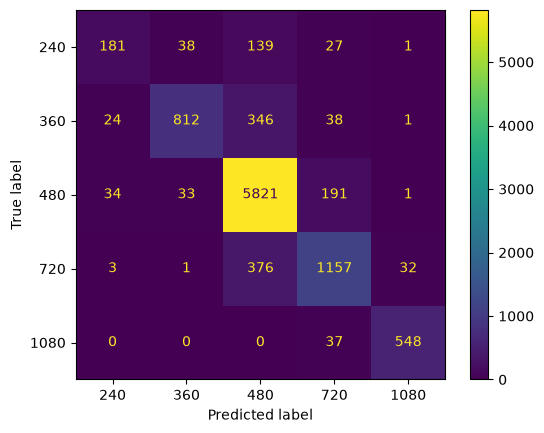

In [58]:
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

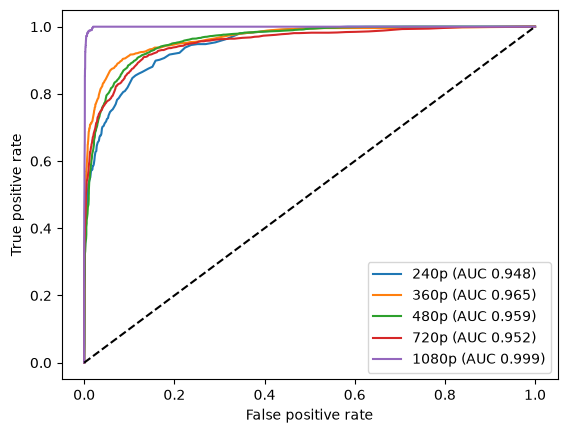

0.9646903213784223


In [59]:
probs = best.predict_proba(x_test)

for n, c in enumerate(best.classes_):
    fpr, tpr, t = roc_curve(y_test == c, probs[:, n])
    auc = roc_auc_score(y_test == c, probs[:, n])
    plt.plot(fpr, tpr, label=str(c) + 'p (AUC ' + str(round(auc, 3)) + ')')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.show()

print(roc_auc_score(y_test, probs, multi_class='ovr'))

## Part 3: Predict the Ongoing Resolution of a Real Netflix Session

Now that you have your model, it's time to put it in practice!

Use a preprocessed Netflix video session to infer **and plot** the resolution at 10-second time intervals. The session is `netflix_session.pkl` (downloaded in Part 2 above; 59 ten-second windows with the same 251 features as `netflix_dataset.pkl`, plus the true `resolution` so you can check yourself):

```python
session = pd.read_pickle('netflix_session.pkl')
```

0.3389830508474576


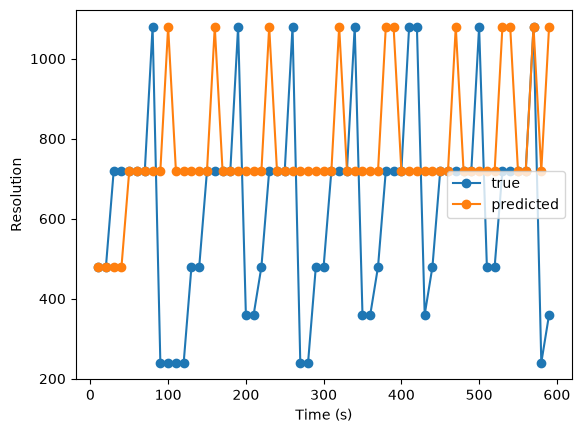

In [60]:
session = pd.read_pickle('data/netflix_session.pkl')

sx = session[x.columns]
sp = best.predict(sx)
st = session['resolution'].astype(int)

print((sp == st).mean())

plt.plot(session['relative_timestamp'], st, 'o-', label='true')
plt.plot(session['relative_timestamp'], sp, 'o-', label='predicted')
plt.xlabel('Time (s)')
plt.ylabel('Resolution')
plt.legend()
plt.show()